# 08. Подготовка к реальному времени

**Вопрос этапа (PROJECT_PLAN.md, этап 8):** поместится ли лучшая сеть на устройство, успеет ли она принять решение
за 50 мс, сохранится ли точность после сжатия до 8 бит и сколько всего проходит от начала жеста до команды?

Итог этапа — **таблица fp32 / int8** (точность, размер, время, операции) и **бюджет задержки** (раздел 8).

Эксперименты (`python run.py --config configs/<имя>.yaml`): `export_dev` — сравнение вариантов квантования на
10 dev-участниках (30 сессий); `export_test` — один прогон на 5 test-участниках (15 сессий) с вариантом и правилом
выбора, замороженными на dev. Код: `src/export.py`, `run_export` в `run.py`. Ноутбук ничего не обучает: результаты
берутся из `results/`, модели — из кэша (`data/cache`).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import onnx
import yaml
from onnx import numpy_helper
from IPython.display import Image, display

import run, adapt, signals, tcn, viz
from data import build_index, REST_GESTURE
from preprocess import ms_to_samples
pd.set_option("display.width", 160)

LABELS = {"torch_fp32": "PyTorch fp32", "fp32": "ONNX fp32", "dynamic": "int8 динамический",
          "static_own": "int8 статич., окна своей калибровки", "static_minmax": "int8 статич., MinMax",
          "static": "int8 статич., Percentile", "static_mixed": "int8, вход в fp32"}


def load(name: str) -> dict | None:
    # Result file results/<name>.json, or None with a hint if the experiment has not been run yet.
    path = ROOT / "results" / f"{name}.json"
    if not path.exists():
        print(f"Результатов ещё нет: python run.py --config configs/{name}.yaml")
        return None
    return json.loads(path.read_text(encoding="utf-8"))


def variants_table(res: dict, dev: dict | None = None) -> pd.DataFrame:
    # Per variant: BA mean ± SD over participants, paired difference with PyTorch fp32, how many participants are
    # worse, the worst session, agreement with fp32, single-thread latency and size; with `dev` also the dev difference.
    def worst(r):
        sc = pd.read_csv(ROOT / r["scores_table"])
        w = 100 * sc.pivot_table(index=["participant", "session"], columns="variant", values="bal_acc")
        return w.sub(w["torch_fp32"], axis=0).min()
    s, b, wst = (pd.DataFrame(res["summary"]).set_index("variant"), pd.DataFrame(res["benchmark"]).set_index("variant"),
                 worst(res))
    rows = {}
    for v in LABELS:
        r, ref = s.loc[v], v == "torch_fp32"
        rows[LABELS[v]] = {
            "BA, %": f"{100 * r['mean']:.1f} ± {100 * r.sd:.1f}",
            "разность, п.п.": "—" if ref else f"{100 * r.diff_mean:+.2f} ± {100 * r.diff_sd:.2f}",
            "хуже": "—" if ref else f"{int(r.n_worse)}/{int(r.n)}",
            "худшая сессия": "—" if ref else f"{wst[v]:+.1f}",
            "совпадение, % (мин)": f"{100 * r.agree_mean:.1f} ({100 * r.agree_min:.1f})",
            "время, мс (p99)": f"{b.loc[v, 'latency_ms_median']:.2f} ({b.loc[v, 'latency_ms_p99']:.2f})",
            "размер, КБ": f"{b.loc[v, 'size_kb']:.0f}"}
        if dev is not None:
            d = pd.DataFrame(dev["summary"]).set_index("variant").loc[v]
            rows[LABELS[v]]["разность dev"] = "—" if ref else f"{100 * d.diff_mean:+.2f}"
    return pd.DataFrame(rows).T


dev, test = load("export_dev"), load("export_test")

## 1. Модель для устройства

**Какую сеть берём:** лучшую в потоке (этап 6) — TCN для нового человека (E3): обучена на других людях, затем
адаптирована к сессии рецептом этапа 5 (AdaBN + дообучение всей сети на калибровке 3×1 с). Дообучение меняет веса,
поэтому каждая сессия экспортируется и квантуется отдельно.

**ONNX** — формат, в котором сеть хранится как граф операций (свёртки, сложения, ReLU) с весами, без Python и PyTorch;
**onnxruntime** — программа, которая исполняет такой граф на CPU, телефоне или встроенном процессоре.

**Форма для устройства:** каждые 50 мс модель получает **одно окно** — последние 205 отсчётов 12 каналов
(200 мс при 1024 Гц) — и возвращает 17 оценок жестов. Рецептивное поле сети (сколько прошлых отсчётов влияет на один
выход) ровно 205 отсчётов, поэтому выход совпадает с потоковым из этапов 4–6.

**Число операций.** MAC — одно умножение со сложением, основная операция свёртки. В форме окна на каждом решении
пересчитываются все 205 позиций; потоковая форма хранила бы прошлые активации каждого слоя и считала только 51 новую
позицию (50 мс).

In [2]:
if dev:
    i = dev["model_info"]
    display(pd.Series({"параметров": f"{i['params']:,}".replace(",", " "),
                       "MAC на одну позицию": f"{i['macs_per_position']:,}".replace(",", " "),
                       "MAC на решение, форма окна": f"{i['macs_window'] / 1e6:.1f} млн",
                       "MAC на решение, потоковая форма": f"{i['macs_streaming'] / 1e6:.1f} млн",
                       "MAC в секунду (окно / поток), 20 решений в с": f"{20 * i['macs_window'] / 1e6:.0f} / {20 * i['macs_streaming'] / 1e6:.0f} млн",
                       "окно vs поток, max |Δ логита|": i["window_vs_stream_max_abs"]}, name="модель").to_frame())

,модель
параметров,151 697
MAC на одну позицию,149 312
"MAC на решение, форма окна",30.6 млн
"MAC на решение, потоковая форма",7.6 млн
"MAC в секунду (окно / поток), 20 решений в с",612 / 152 млн
"окно vs поток, max |Δ логита|",0.0


## 2. Квантование int8

**Квантование** — хранить и считать числа не как float32 (4 байта), а как целые int8 (1 байт, 256 значений). Тензор
описывается масштабом s и нулевой точкой z:

$$x \approx s\,(q - z),\qquad q = \mathrm{round}(x / s) + z,\qquad s = \frac{\max - \min}{255}$$

Ошибка округления — не больше полшага s/2. **Post-training** — квантуется уже обученная сеть, без переобучения.

**Зачем квантовать и веса, и активации.** Если в int8 только веса, их перед умножением всё равно переводят во float —
экономится память, но не вычисления. Целочисленная свёртка $y_o \approx s_{w,o}\, s_x \sum q_w q_x$ требует, чтобы
целыми были **оба** множителя; тогда умножения int8 × int8 с накоплением в int32 быстрее (в векторный регистр
помещается вчетверо больше чисел) и в разы дешевле по энергии, а activations занимают вчетверо меньше памяти.

**Веса** известны после обучения — их диапазон считается точно, **свой масштаб на каждый выходной канал свёртки**
(per-channel). Масштаб, постоянный внутри одной суммы $\sum q_w q_x$, выносится за скобку бесплатно — поэтому
по выходным, а не по входным каналам. Ниже — насколько различаются фильтры одной из адаптированных моделей
(BatchNorm при экспорте вмонтирован в свёртки, отсюда разный масштаб фильтров).

In [3]:
g = onnx.load(str(ROOT / "data/cache/onnx/export_dev/fp32.onnx")).graph
init = {i.name: numpy_helper.to_array(i) for i in g.initializer}
rows = []
for n in g.node:
    if n.op_type != "Conv" or n.input[1] not in init:
        continue
    w = init[n.input[1]]
    a = np.abs(w).reshape(w.shape[0], -1).max(1)                      # max |w| of every output channel
    err = lambda s: np.sqrt(((np.clip(np.round(w / s), -127, 127) * s - w) ** 2).reshape(w.shape[0], -1).mean(1)) \
        / np.sqrt((w ** 2).reshape(w.shape[0], -1).mean(1))
    rows.append({"слой": n.name.replace("/model/", "").replace("/Conv", ""), "форма": str(w.shape),
                 "разброс max|w| между фильтрами": f"×{a.max() / a.min():.1f}",
                 "уровней у слабого фильтра при одном масштабе": f"{a.min() / (np.abs(w).max() / 127):.0f} из 127",
                 "ошибка худшего фильтра: один масштаб → по каналам, %":
                     f"{100 * err(np.abs(w).max() / 127).max():.1f} → {100 * err((a / 127).reshape(-1, *[1] * (w.ndim - 1))).max():.1f}"})
display(pd.DataFrame(rows).set_index("слой"))

,форма,разброс max|w| между фильтрами,уровней у слабого фильтра при одном масштабе,"ошибка худшего фильтра: один масштаб → по каналам, %"
слой,,,,
stem,"(64, 12, 1)",×2.8,45 из 127,1.2 → 0.6
blocks/blocks.0/net/net.0,"(64, 64, 3)",×4.2,30 из 127,3.3 → 1.3
blocks/blocks.0/net/net.4,"(64, 64, 3)",×2.9,44 из 127,1.8 → 1.3
blocks/blocks.1/net/net.0,"(64, 64, 3)",×2.1,59 из 127,1.3 → 1.1
blocks/blocks.1/net/net.4,"(64, 64, 3)",×2.3,55 из 127,1.5 → 1.0
blocks/blocks.2/net/net.0,"(64, 64, 3)",×2.3,55 из 127,1.5 → 0.9
blocks/blocks.2/net/net.4,"(64, 64, 3)",×2.4,53 из 127,1.5 → 1.0
blocks/blocks.3/net/net.0,"(64, 64, 3)",×2.5,50 из 127,1.9 → 1.1
blocks/blocks.3/net/net.4,"(64, 64, 3)",×2.6,49 из 127,1.9 → 1.0


**Активации** (выходы слоёв) зависят от входа, поэтому их диапазон надо либо мерить, либо угадать заранее:

| | диапазон активаций | между слоями | плюс | минус |
|---|---|---|---|---|
| **динамическое** | меряется на каждом вызове по текущему окну | float | шкала всегда под сигнал | лишний проход по данным и перевод float ↔ int8 перед каждым слоем |
| **статическое** | фиксируется заранее по **окнам квантования** | int8 | всё целочисленное, быстро, время вызова постоянно | точность зависит от того, похожи ли окна на будущий сигнал |

**Окна квантования** — не путать с калибровкой пользователя (3×1 с, дообучение): через fp32-модель прогоняются
типичные входы, по ним выбирается диапазон каждого тензора. **MinMax** — от минимума до максимума (один выброс
растягивает шкалу для всех); **Percentile** — 0,001–99,999 % (редкие выбросы обрезаются, шаг мельче). Это выбор
между ошибкой округления (шаг s, среднеквадратично ≈ s/√12) и ошибкой обрезки.

## 3. Где 8 бит не хватает: вход

Ниже — нормированный вход сети x / scale (в единицах SD канала) на тестовых попытках той сессии, чью модель мы
только что разбирали, и **шаг квантования этого тензора**, взятый из полностью статического int8-файла (Percentile,
окна других людей). Значения меньше полшага округляются в ноль.

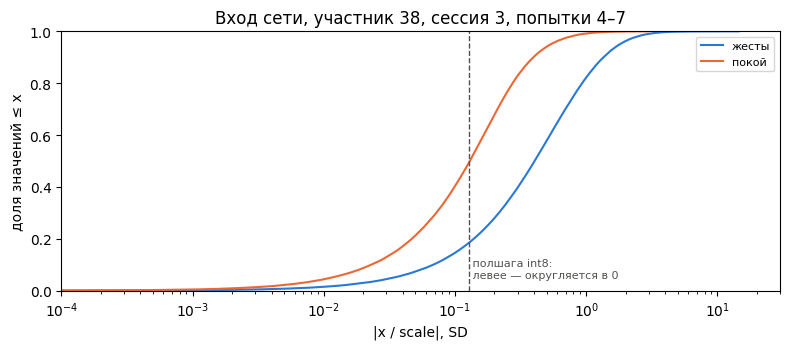

шаг квантования входа 0.258 SD (диапазон ≈ 65.7 SD)
покой: медиана |x| = 0.130 SD = 0.50 шага; в ноль округляется 50 % значений
жесты: медиана |x| = 0.405 SD = 1.57 шага; в ноль округляется 19 % значений


In [4]:
cfg = yaml.safe_load((ROOT / "configs/export_dev.yaml").read_text(encoding="utf-8"))
ps = run.resolve_participants("dev")
idx = build_index(); idx = idx[idx.participant.isin(ps)]
meta, X = signals.signal_table(idx, cfg["preprocess"])
cfg = {**cfg, "crop": ms_to_samples(cfg["train"]["crop_ms"], 1024)}
split = run._target_splits(meta, "E3", cfg, None)[-1]                       # the last session run.py exported
p, s = sorted(meta[split.test].groupby(["participant", "session"]).indices)[-1]
sess = split.test & (meta.participant.to_numpy() == p) & (meta.session.to_numpy() == s) & (meta.trial.to_numpy() > 3)

div = next(n for n in g.node if n.op_type == "Div")
scale = init[div.input[1]].reshape(1, -1, 1)
xs = X[sess] / scale                                                         # what the first convolution sees
q = onnx.load(str(ROOT / "data/cache/onnx/export_dev/static.onnx")).graph
qinit = {i.name: numpy_helper.to_array(i) for i in q.initializer}
qn = next(n for n in q.node if n.op_type == "QuantizeLinear" and n.input[0] == div.output[0])
step = float(qinit[qn.input[1]])
rest = meta.gesture.to_numpy()[sess] == REST_GESTURE

fig, ax = plt.subplots(figsize=(8, 3.6))
for v, label, c in [(np.abs(xs[~rest]).ravel(), "жесты", viz.SERIES[0]), (np.abs(xs[rest]).ravel(), "покой", viz.SERIES[1])]:
    v = np.sort(v)[::50]                                                     # thinned for plotting
    ax.plot(v, np.linspace(0, 1, len(v)), color=c, lw=1.5, label=label)
ax.axvline(step / 2, color=viz.INK_2, ls="--", lw=1)
ax.text(step / 2, 0.05, " полшага int8:\n левее — округляется в 0", fontsize=8, color=viz.INK_2)
ax.set(xscale="log", xlim=(1e-4, 30), ylim=(0, 1), xlabel="|x / scale|, SD", ylabel="доля значений ≤ x",
       title=f"Вход сети, участник {p}, сессия {s}, попытки 4–7")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"шаг квантования входа {step:.3f} SD (диапазон ≈ {255 * step:.1f} SD)")
for v, label in [(xs[rest], "покой"), (xs[~rest], "жесты")]:
    print(f"{label}: медиана |x| = {np.median(np.abs(v)):.3f} SD = {np.median(np.abs(v)) / step:.2f} шага; "
          f"в ноль округляется {100 * (np.abs(v) < step / 2).mean():.0f} % значений")

**Как читать:** кривая — доля значений входа не больше x; всё левее пунктира int8-модель видит как ноль. Диапазон
входа задают редкие выбросы окон квантования (≈ 66 SD на 256 уровней), поэтому шаг крупный: **половина значений покоя
и пятая часть значений жестов округляются в ноль**, медиана покоя — полшага, медиана жестов — полтора шага.
Восьми бит не хватает на **динамический диапазон** ЭМГ (покой и сильное сокращение различаются в десятки раз). Это та же история, что с разрядностью АЦП датчика. Стёртое на входе сеть уже не восстановит;
после первой свёртки информация размазана по 64 признакам с почти независимыми ошибками округления, и следующие слои
их частично усредняют (вероятное объяснение, почему внутренние слои 8 бит переносят).

**Решение — смешанная точность:** деление на масштаб и первая свёртка 1×1 (stem, 12 → 64 канала) остаются во float,
с выхода stem — int8 со статическими масштабами. Stem — 768 из 149 312 MAC на позицию (0,5 %), поэтому по скорости
это почти бесплатно.

## 4. Варианты и правило выбора

| вариант | веса | активации | окна квантования |
|---|---|---|---|
| ONNX fp32 | float | float | — |
| int8 динамический | int8 | диапазон на каждом вызове | — |
| int8 статич., окна своей калибровки | int8 | MinMax | первая секунда каждого жеста в попытках 1–3 этой сессии |
| int8 статич., MinMax | int8 | MinMax | 1000 случайных окон обучающих людей |
| int8 статич., Percentile | int8 | Percentile | те же |
| **int8, вход в fp32** | int8 (кроме stem) | Percentile, вход и stem во float | те же |

**Показатели** (тестовые попытки 4–7 каждой сессии): BA (balanced accuracy) — среднее по сессиям участника, затем
по участникам; **разность с PyTorch fp32 попарно** — сколько стоило именно квантование; **худшая сессия** — риск для
отдельного пользователя; **совпадение** — доля окон с тем же классом, что у fp32 (чувствительнее BA: перебросы
классов в обе стороны в BA частично гасятся); **время одного решения** — окно, batch 1, один поток CPU ноутбука,
2000 вызовов: медиана и 99-й перцентиль (в реальном времени важно и почти худшее); **размер файла**.

**Правило выбора (dev):** (1) отбросить варианты, которые не быстрее ONNX fp32; (2) из остальных — наименьшая потеря
точности к PyTorch fp32, в среднем и в худшей сессии.

## 5. Результаты на dev (10 участников, 30 сессий)

finished 2026-10-28T19:38:10


,"BA, %","разность, п.п.",хуже,худшая сессия,"совпадение, % (мин)","время, мс (p99)","размер, КБ"
PyTorch fp32,81.0 ± 3.7,—,—,—,100.0 (100.0),2.52 (3.52),599
ONNX fp32,81.0 ± 3.7,-0.00 ± 0.01,5/10,-0.0,100.0 (99.9),0.54 (0.82),628
int8 динамический,81.0 ± 3.5,-0.00 ± 0.22,4/10,-0.8,98.0 (97.0),6.81 (7.77),197
"int8 статич., окна своей калибровки",77.8 ± 5.3,-3.16 ± 4.54,9/10,-42.2,91.4 (76.9),0.24 (0.39),215
"int8 статич., MinMax",71.9 ± 7.3,-9.15 ± 8.15,10/10,-34.9,81.2 (63.8),0.24 (0.45),215
"int8 статич., Percentile",76.4 ± 4.8,-4.61 ± 4.60,9/10,-21.8,88.8 (77.6),0.24 (0.43),215
"int8, вход в fp32",80.4 ± 3.9,-0.58 ± 0.58,8/10,-2.5,96.0 (93.1),0.26 (0.40),215


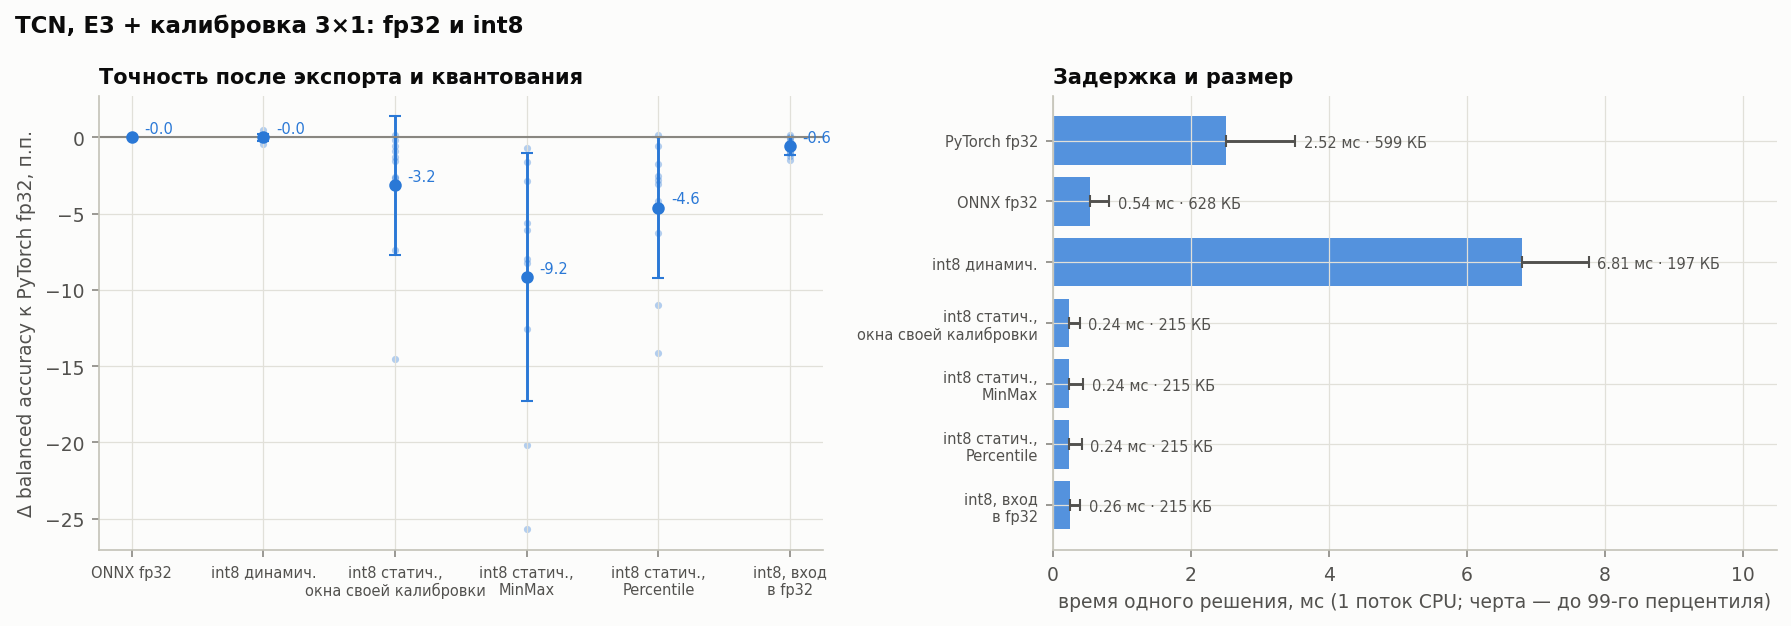

In [5]:
if dev:
    print("finished", dev["finished"])
    display(variants_table(dev))
    display(Image(ROOT / dev["figures"][0]))

**Как читать график:** слева — изменение BA относительно PyTorch fp32 у каждого участника (точки) и среднее ± SD;
справа — время одного решения (медиана, черта — до 99-го перцентиля) и размер файла.

1. **Экспорт в ONNX бесплатен и в 4,6 раза ускоряет модель** (2,52 → 0,54 мс): у маленькой сети накладные расходы
   PyTorch больше самих вычислений.
2. **Полностью статический int8 ненадёжен:** −3…−9 п.п. в среднем, до −42 п.п. в отдельной сессии. Percentile лучше
   MinMax, но проблему входа не снимает.
3. **Вход во float решает её:** −0,6 ± 0,6 п.п., худшая сессия −2,5, совпадение с fp32 96 % — при той же скорости,
   что у полного int8.
4. **Динамический int8 точен (±0,2 п.п.), но в 12 раз медленнее fp32** на этом CPU — выбывает по правилу (1).
5. **Выбор для test — «int8, вход в fp32»**: 628 → 215 КБ, 0,54 → 0,26 мс.

## 6. Итог на test (5 участников, 15 сессий, один прогон)

finished 2026-10-28T20:44:22


,"BA, %","разность, п.п.",хуже,худшая сессия,"совпадение, % (мин)","время, мс (p99)","размер, КБ",разность dev
PyTorch fp32,83.6 ± 7.5,—,—,—,100.0 (100.0),2.53 (3.49),599,—
ONNX fp32,83.6 ± 7.5,-0.01 ± 0.01,3/5,-0.0,100.0 (100.0),0.55 (0.90),628,-0.00
int8 динамический,83.6 ± 7.2,-0.03 ± 0.38,4/5,-0.7,97.8 (96.0),6.90 (7.93),197,-0.00
"int8 статич., окна своей калибровки",82.3 ± 8.1,-1.34 ± 0.91,5/5,-5.9,93.8 (88.2),0.24 (0.40),215,-3.16
"int8 статич., MinMax",75.5 ± 6.2,-8.11 ± 3.71,5/5,-22.3,83.3 (80.3),0.24 (0.43),215,-9.15
"int8 статич., Percentile",80.5 ± 7.5,-3.16 ± 1.40,5/5,-9.1,90.6 (85.3),0.24 (0.44),215,-4.61
"int8, вход в fp32",82.9 ± 7.7,-0.76 ± 0.79,5/5,-6.0,96.2 (93.2),0.26 (0.48),215,-0.58


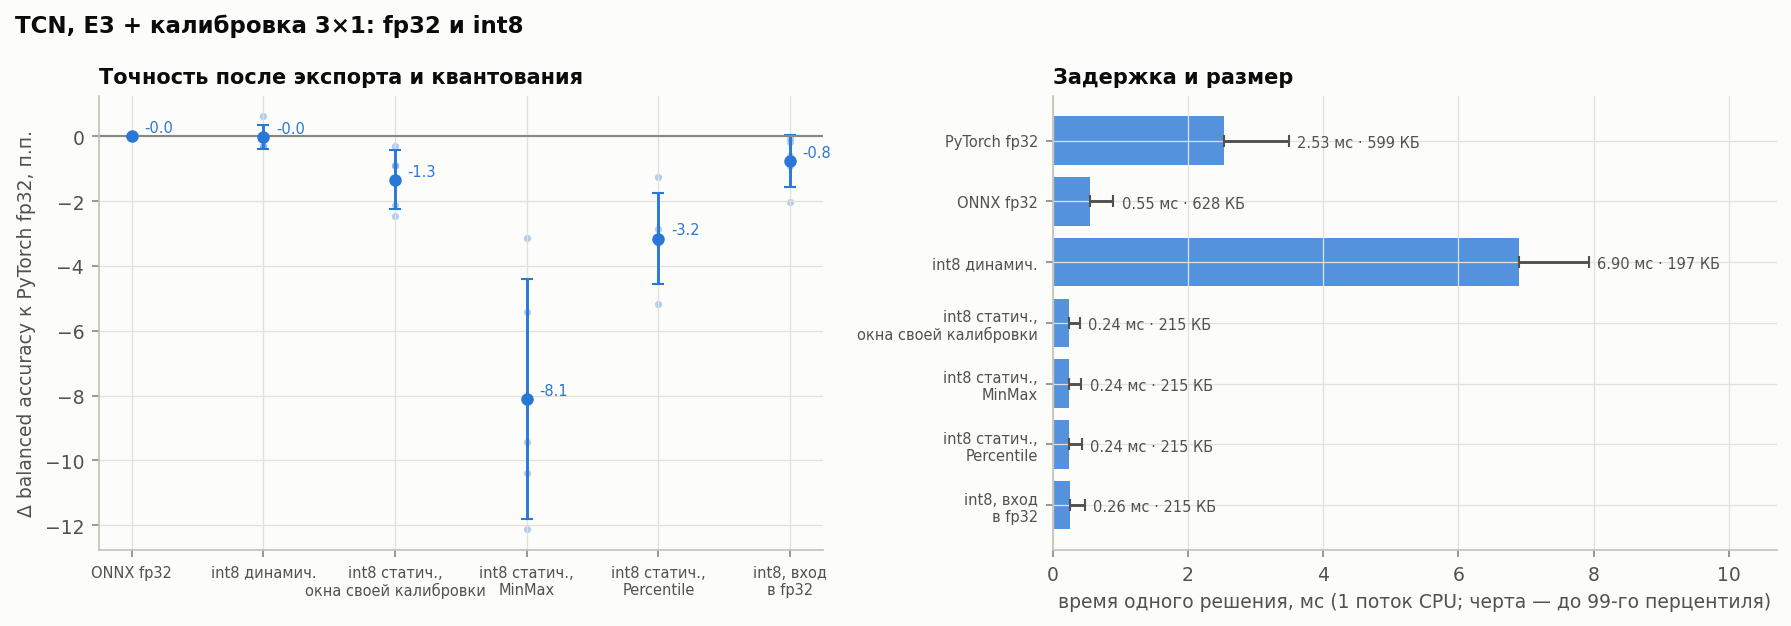

In [6]:
if test:
    print("finished", test["finished"])
    display(variants_table(test, dev))
    display(Image(ROOT / test["figures"][0]))

Контроль: PyTorch fp32 совпадает с этапом 5 до 4·10⁻⁵, ONNX fp32 — с PyTorch в 99,98 % окон.

1. **Выбор с dev подтвердился:** −0,8 ± 0,8 п.п. (dev −0,6); хуже у всех 5, но от −0,1 до −2,0 п.п. на участника;
   худшая сессия −6,0 — «хвост» на test тяжелее, чем на dev.
2. **Порядок вариантов тот же, что на dev:** полностью статический int8 теряет 3–8 п.п., динамический точен,
   но медленнее fp32.
3. **Модель в 2,9 раза меньше, в 2,2 раза быстрее ONNX fp32 и в 10 раз быстрее PyTorch.**

## 7. Бюджет задержки: от начала жеста до команды

Задержку команды (медиана «верная команда − начало жеста») мы измерили на этапе 6. Перебор постобработки на dev
содержит задержку для каждой настройки, и разность между настройками, отличающимися одной «ручкой», даёт цену этой
ручки. Что остаётся без постобработки — реакция самой модели: **групповая задержка фильтра** (на сколько фильтр
сдвигает сигнал во времени), ожидание ближайшего решения на сетке 50 мс (в среднем половина шага) и время, пока
окно 200 мс наберёт достаточно жеста. Инференса в замере этапа 6 не было — он добавлен отдельно. На test перебора
нет (только замороженная точка), поэтому разложение — по dev, итог — и dev, и test.

,ms,source
component,,
фильтр 20–450 Гц: групповая задержка на пике спектра,3.7,рассчитано
сетка решений: ожидание следующего решения (шаг / 2),25.0,оценка
окно 200 мс: накопление жеста до уверенного решения,67.6,этап 6 − две строки выше
сглаживание τ = 250 мс,180.1,этап 6
минимальная длительность 100 мс,102.0,этап 6
"инференс (CPU ноутбука, 1 поток)",0.3,этап 8
итого (dev),378.6,"этап 6, dev: 378 мс + инференс"
итого (test),378.2,"этап 6, test: 378 мс + инференс"


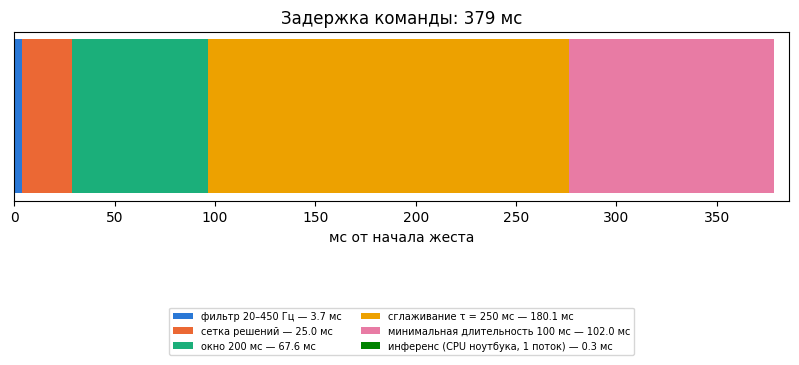

,"сглаживание, мс","мин. длит., мс",порог,верные,ложные/мин покоя,лишние на жест,"задержка, мс"
настройка,,,,,,,
рабочая точка,250,100,0.5,86.2,0.90,0.07,378.35
≤ 250 мс,0,100,0.8,85.6,0.66,0.33,245.30
≤ 250 мс,100,0,0.7,84.3,0.92,0.31,224.24
≤ 250 мс,0,100,0.7,84.1,0.87,0.35,230.74


In [7]:
if test:
    b = pd.DataFrame(test["latency_budget"])
    display(b.assign(ms=b.ms.round(1)).set_index("component"))
    parts = b[~b.component.str.startswith("итого")]
    fig, ax = plt.subplots(figsize=(10, 2.2))
    left = 0
    for (_, r), c in zip(parts.iterrows(), viz.SERIES):
        ax.barh([0], [r.ms], left=left, color=c, label=f"{r.component.split(':')[0]} — {r.ms:.1f} мс")
        left += r.ms
    ax.set(yticks=[], xlabel="мс от начала жеста", xlim=(0, 1.02 * left), title=f"Задержка команды: {left:.0f} мс")
    ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.6), ncol=2)
    plt.show()

    # what a faster command would cost: the best dev settings with latency <= 250 ms
    c = pd.DataFrame(load("stream_dev")["curves_mean"])
    c = c[(c.model == "tcn") & (c.experiment == "E3") & (c.refractory_ms == 750)]
    cols = {"tau_ms": "сглаживание, мс", "min_ms": "мин. длит., мс", "theta": "порог", "correct": "верные",
            "fa_per_min": "ложные/мин покоя", "extra_per_gesture": "лишние на жест", "latency_ms_median": "задержка, мс"}
    op = c[(c.tau_ms == 250) & (c.min_ms == 100) & np.isclose(c.theta, 0.5)].assign(настройка="рабочая точка")
    fast = c[c.latency_ms_median <= 250].sort_values("correct", ascending=False).head(3).assign(настройка="≤ 250 мс")
    t = pd.concat([op, fast])[["настройка"] + list(cols)].rename(columns=cols)
    t["верные"] = (100 * t["верные"]).round(1)
    display(t.round(2).set_index("настройка"))

1. **Инференс — 0,07 % задержки.** Задержку определяет постобработка: сглаживание и минимальная длительность —
   282 мс из 378. Ускорять сеть ради задержки бессмысленно; квантование нужно ради памяти, энергии и слабого
   процессора браслета.
2. **Сокращать задержку — через постобработку, и платить повторными командами:** при ≤ 250 мс доля верных почти та же,
   ложные в покое держатся порогом, но лишних команд на жест в 4–5 раз больше (≈ каждый третий жест).
3. **Дешёвые резервы:** шаг решений 25 мс вместо 50 (инференс 0,26 мс — вдвое больше вызовов почти бесплатно,
   −12 мс ожидания); **гистерезис** — высокий порог для срабатывания и низкий для отпускания — вместо сильного
   сглаживания.

## 8. Итог этапа 8

| test | BA | потеря к fp32 | худшая сессия | размер | время решения* | MAC на решение |
|---|---|---|---|---|---|---|
| PyTorch fp32 | 83,6 % | — | — | 599 КБ | 2,53 мс | 30,6 млн |
| ONNX fp32 | 83,6 % | 0,0 п.п. | 0,0 | 628 КБ | 0,55 мс | 30,6 млн |
| **ONNX int8, вход в fp32** | **82,9 %** | **−0,8 п.п.** | −6,0 | **215 КБ** | **0,26 мс** | 30,6 млн (7,6 млн в потоковой форме) |

\* один поток CPU ноутбука (i7-14650HX), batch 1, медиана. **Задержка команды:** 378 мс, из них инференс 0,26 мс.

**Выводы**
1. **Сеть помещается и успевает с огромным запасом:** 215 КБ, 0,26 мс при бюджете 50 мс на решение.
2. **8-битное квантование ломается на входе** — там динамический диапазон ЭМГ шире 256 уровней; смешанная точность
   (вход и первая свёртка во float, 0,5 % операций) сохраняет точность (−0,8 п.п.) при скорости полного int8.
3. **Окна квантования важны не меньше метода:** окна из начала жеста дают выбросы, MinMax по ним растягивает шкалу.
4. **Задержку команды задаёт постобработка, а не модель.**

**Ограничения:** время измерено на CPU ноутбука — на процессор браслета переносится только число операций (30,6 млн
MAC на решение, 610 млн в секунду; в потоковой форме — 150 млн), а float в первой свёртке требует блока плавающей
точки; потоковые метрики этапа 6 с int8 не пересчитаны (судим по точности окон); обучение с учётом квантования (QAT)
и 16-битный вход не проверялись; один сид.

**Что бы улучшить:** потоковая форма с кэшем активаций (×4 меньше операций); int16 на входе вместо float для чипов
без плавающей точки; QAT; замер на целевом процессоре; гистерезис в постобработке.

## Проверь себя
1. Почему 8-битное квантование ломается именно на входе сети, а дальше по слоям почти не вредит?
2. Почему динамический int8 точнее статического, но медленнее даже fp32? Что он делает на каждом вызове?
3. Если продукту нужно сократить задержку команды с 380 до 250 мс, какие звенья бюджета ты бы трогал и чем за это
   придётся заплатить?